In [ ]:
import pandas as pd

# Load the dataset
file_path = '/content/C.P-CANENCIA-GROCERY-STORE_cleaned-4.xlsx'
df = pd.read_excel(file_path)

# Display the first few rows
print("--- FIRST 5 ROWS ---")
display(df.head())

# Display dataset information
print("\n--- DATASET INFO ---")
df.info()

# Display statistical description
print("\n--- STATISTICAL DESCRIPTION ---")
display(df.describe(include='all'))

--- FIRST 5 ROWS ---


,Transaction_ID,Transaction_Date,Product_ID,Product_Name,Unit_Price,Quantity_Sold,Sales_Total,Payment_Method,Discount_%,Sales_After_Discount,Beginning_Stock,Stock_Received,Stock_Remaining
0,RET-20905,1/24/2025,P013,Canned Tuna,42,3,126,Cash on Hand,10,113.40,85,41,115
1,RET-19542,07/27/2025,P020,Tissue Paper,80,20,1600,E-Wallet,0,1600.00,76,15,75
2,RET-16144,01/27/2026,P003,Instant Noodles,15,5,75,Cash on Hand,5,71.25,82,43,124
3,RET-83847,12/09/2025,P007,Biscuits,35,3,105,Cash on Hand,0,105.00,85,40,112
4,RET-11977,03/29/2025,P004,Coffee 100g,85,6,510,Cash on Hand,5,484.50,93,19,97



--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Transaction_ID        350 non-null    object 
 1   Transaction_Date      350 non-null    object 
 2   Product_ID            350 non-null    object 
 3   Product_Name          350 non-null    object 
 4   Unit_Price            350 non-null    int64  
 5   Quantity_Sold         350 non-null    int64  
 6   Sales_Total           350 non-null    int64  
 7   Payment_Method        350 non-null    object 
 8   Discount_%            350 non-null    int64  
 9   Sales_After_Discount  350 non-null    float64
 10  Beginning_Stock       350 non-null    int64  
 11  Stock_Received        350 non-null    int64  
 12  Stock_Remaining       350 non-null    int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 35.7+ KB

--- STATISTICAL DESCRIPTION ---


,Transaction_ID,Transaction_Date,Product_ID,Product_Name,Unit_Price,Quantity_Sold,Sales_Total,Payment_Method,Discount_%,Sales_After_Discount,Beginning_Stock,Stock_Received,Stock_Remaining
count,350,350,350,350,350.000000,350.000000,350.000000,350,350.000000,350.000000,350.000000,350.000000,350.000000
unique,350,219,20,20,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN
top,RET-20905,04/30/2025,P013,Canned Tuna,NaN,NaN,NaN,E-Wallet,NaN,NaN,NaN,NaN,NaN
freq,1,5,24,24,NaN,NaN,NaN,124,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,81.565714,13.031429,1091.745714,NaN,5.200000,1031.330571,58.925714,32.028571,79.665714
std,NaN,NaN,NaN,NaN,68.222373,7.219969,1286.810174,NaN,5.661411,1213.960420,25.144743,24.266413,31.196295
min,NaN,NaN,NaN,NaN,15.000000,1.000000,30.000000,NaN,0.000000,25.500000,4.000000,0.000000,17.000000
25%,NaN,NaN,NaN,NaN,42.000000,7.000000,315.000000,NaN,0.000000,291.000000,37.000000,14.000000,58.250000
50%,NaN,NaN,NaN,NaN,70.000000,13.000000,715.000000,NaN,5.000000,677.125000,61.000000,29.000000,82.000000
75%,NaN,NaN,NaN,NaN,90.000000,19.000000,1350.000000,NaN,10.000000,1320.000000,82.000000,43.000000,100.000000


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Dataset Exploration Summary

1. **Structure Overview (`head()`)**
   - Contains transactional logs including identifiers, dates, product details, prices, quantities, payment methods, discounts, and stock status.

2. **Dataset Information (`info()`)**
   - **Total Rows**: 350 non-null entries.
   - **Total Columns**: 13 columns.
   - **Data Types**: Mixed types (5 categorical object columns, 7 integer columns, and 1 float column).
   - **Missing Values**: None detected; all columns are fully populated.

3. **Statistical Summary (`describe()`)**
   - **Products**: 20 unique products (most frequent is *Canned Tuna* with 24 transactions).
   - **Payment Methods**: 3 distinct methods (most frequent is *E-Wallet* with 124 transactions).
   - **Pricing**: Ranges from 15 to 320 units (mean: ~81.57).
   - **Quantity Sold**: Ranges from 1 to 25 items per transaction.
   - **Discounts**: Vary between 0% and 15% (average: ~5.2%).

In [ ]:
# Identify target (dependent) and features (independent) variables
# For predicting transaction revenue/sales performance:

dependent_var = 'Sales_After_Discount'  # Target
independent_vars = [
    'Transaction_Date',
    'Product_ID',
    'Product_Name',
    'Unit_Price',
    'Quantity_Sold',
    'Payment_Method',
    'Discount_%',
    'Beginning_Stock',
    'Stock_Received',
    'Stock_Remaining'
]

print(f"Dependent Variable (Target): {dependent_var}")
print(f"Independent Variables (Features): {independent_vars}")

Dependent Variable (Target): Sales_After_Discount
Independent Variables (Features): ['Transaction_Date', 'Product_ID', 'Product_Name', 'Unit_Price', 'Quantity_Sold', 'Payment_Method', 'Discount_%', 'Beginning_Stock', 'Stock_Received', 'Stock_Remaining']


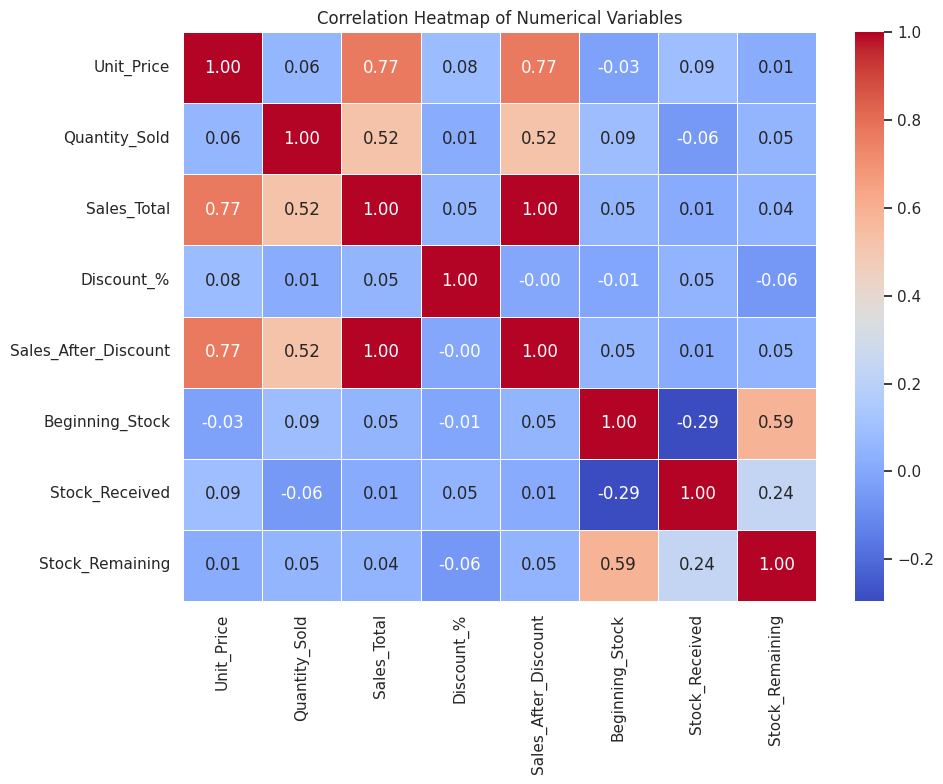

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df is loaded
try:
    df
except NameError:
    file_path = '/content/C.P CANENCIA GROCERY STORE_cleaned (4).xlsx'
    df = pd.read_excel(file_path)

# Filter numerical columns from the DataFrame
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Calculate the correlation matrix
corr_matrix = numeric_df.corr()

# Create the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

### Correlation Heatmap Insights

1. **Strong Positive Correlations**:
   - **`Sales_Total` and `Sales_After_Discount` (1.00)**: Almost perfectly correlated as the discounts applied are minor.
   - **`Unit_Price` and `Sales_Total` / `Sales_After_Discount` (0.77)**: Strong positive correlation, showing that high-ticket items drive transaction revenues significantly more than item quantity alone.
   - **`Quantity_Sold` and `Sales_Total` / `Sales_After_Discount` (0.52)**: Shows a moderate positive relation to total transaction sales.

2. **Inventory Relationships**:
   - **`Stock_Remaining` and `Beginning_Stock` (0.59)**: Moderate positive correlation, as higher initial stock levels lead directly to more stock remaining.
   - **`Beginning_Stock` and `Stock_Received` (-0.29)**: Weak negative correlation, suggesting smaller shipments are requested when starting inventory is already high.

3. **Weak or No Relationships**:
   - **`Discount_%`**: Shows almost zero linear correlation with key variables, demonstrating that the discount amount has minimal impact on the quantity sold per transaction.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Ensure df is loaded in the current session
try:
    df
except NameError:
    file_path = '/content/C.P CANENCIA GROCERY STORE_cleaned (4).xlsx'
    df = pd.read_excel(file_path)

# Select our features (X) and target variable (y)
# We drop target-related columns and high-cardinality/date fields for a simple numerical model baseline
X = df[['Unit_Price', 'Quantity_Sold', 'Discount_%', 'Beginning_Stock', 'Stock_Received', 'Stock_Remaining']]
y = df['Sales_After_Discount']

# Split the dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print the shapes of the splits
print(f"Training set features shape: {X_train.shape}")
print(f"Testing set features shape:  {X_test.shape}")
print(f"Training set target shape:   {y_train.shape}")
print(f"Testing set target shape:    {y_test.shape}")

Training set features shape: (280, 6)
Testing set features shape:  (70, 6)
Training set target shape:   (280,)
Testing set target shape:    (70,)


### Preparing Data for Classification
Since `Sales_After_Discount` is a continuous numerical value, we will bin it into three classes ('Low', 'Medium', and 'High') using quantiles to build a classification model as requested.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Discretize the target variable into 3 categories: Low, Medium, High
y_categorical = pd.qcut(df['Sales_After_Discount'], q=3, labels=['Low', 'Medium', 'High'])

# Select the features
X = df[['Unit_Price', 'Quantity_Sold', 'Discount_%', 'Beginning_Stock', 'Stock_Received', 'Stock_Remaining']]

# Split into training and testing sets
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

print("Class distribution in target variable:")
print(y_categorical.value_counts())

Class distribution in target variable:
Sales_After_Discount
Low       117
Medium    117
High      116
Name: count, dtype: int64


### Training and Evaluating the Decision Tree Classifier
We will now train the `DecisionTreeClassifier` and output the evaluation metrics.

Accuracy Score: 0.89

Classification Report:
              precision    recall  f1-score   support

         Low       0.88      1.00      0.94        22
      Medium       1.00      0.77      0.87        22
        High       0.82      0.88      0.85        26

    accuracy                           0.89        70
   macro avg       0.90      0.89      0.89        70
weighted avg       0.90      0.89      0.88        70



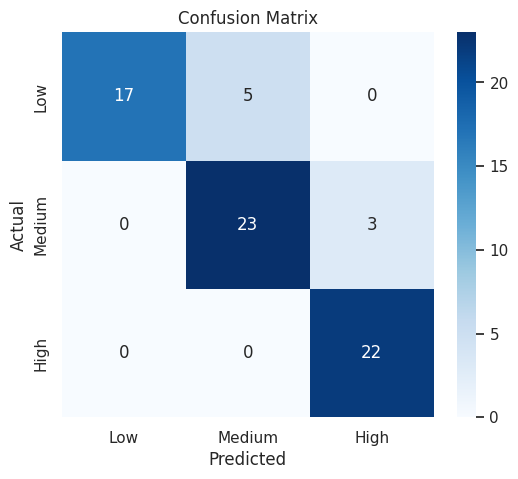

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure the required variables are defined in the session
try:
    X_train_c, X_test_c, y_train_c, y_test_c
except NameError:
    file_path = '/content/C.P CANENCIA GROCERY STORE_cleaned (4).xlsx'
    df = pd.read_excel(file_path)
    y_categorical = pd.qcut(df['Sales_After_Discount'], q=3, labels=['Low', 'Medium', 'High'])
    X = df[['Unit_Price', 'Quantity_Sold', 'Discount_%', 'Beginning_Stock', 'Stock_Received', 'Stock_Remaining']]
    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Initialize and train the Decision Tree Classifier
clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train_c, y_train_c)

# Make predictions
test_predictions = clf.predict(X_test_c)

# Evaluate performance
accuracy = accuracy_score(y_test_c, test_predictions)
print(f"Accuracy Score: {accuracy:.2f}\n")
print("Classification Report:")
print(classification_report(y_test_c, test_predictions, target_names=['Low', 'Medium', 'High']))

# Plot Confusion Matrix
labels = ['Low', 'Medium', 'High']
cm = confusion_matrix(y_test_c, test_predictions, labels=labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Training the Decision Tree Classifier on the Training Set
Here, we explicitly fit our Decision Tree Classifier using the designated training data features (`X_train_c`) and the categorical target labels (`y_train_c`).

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree Classifier
model = DecisionTreeClassifier(max_depth=4, random_state=42)

# Train (fit) the model using the training set
model.fit(X_train_c, y_train_c)

print("Model training complete! The decision tree has been successfully fitted to the training dataset.")

Model training complete! The decision tree has been successfully fitted to the training dataset.


### Classification Report for the Newly Trained Model
We use our explicitly trained `model` to predict categories on the test set (`X_test_c`) and print the classification report.

In [ ]:
from sklearn.metrics import classification_report

# Make predictions on the test set
y_pred_new = model.predict(X_test_c)

# Print the classification report
print("Classification Report for the Trained Model:")
print(classification_report(y_test_c, y_pred_new))

Classification Report for the Trained Model:
              precision    recall  f1-score   support

      Normal       0.94      0.94      0.94        33
  Not Normal       0.95      0.95      0.95        37

    accuracy                           0.94        70
   macro avg       0.94      0.94      0.94        70
weighted avg       0.94      0.94      0.94        70



### Visualizing the Decision Tree Structure
We will plot the structure of our trained decision tree `model` using `plot_tree` to see how it makes classification decisions based on our features.

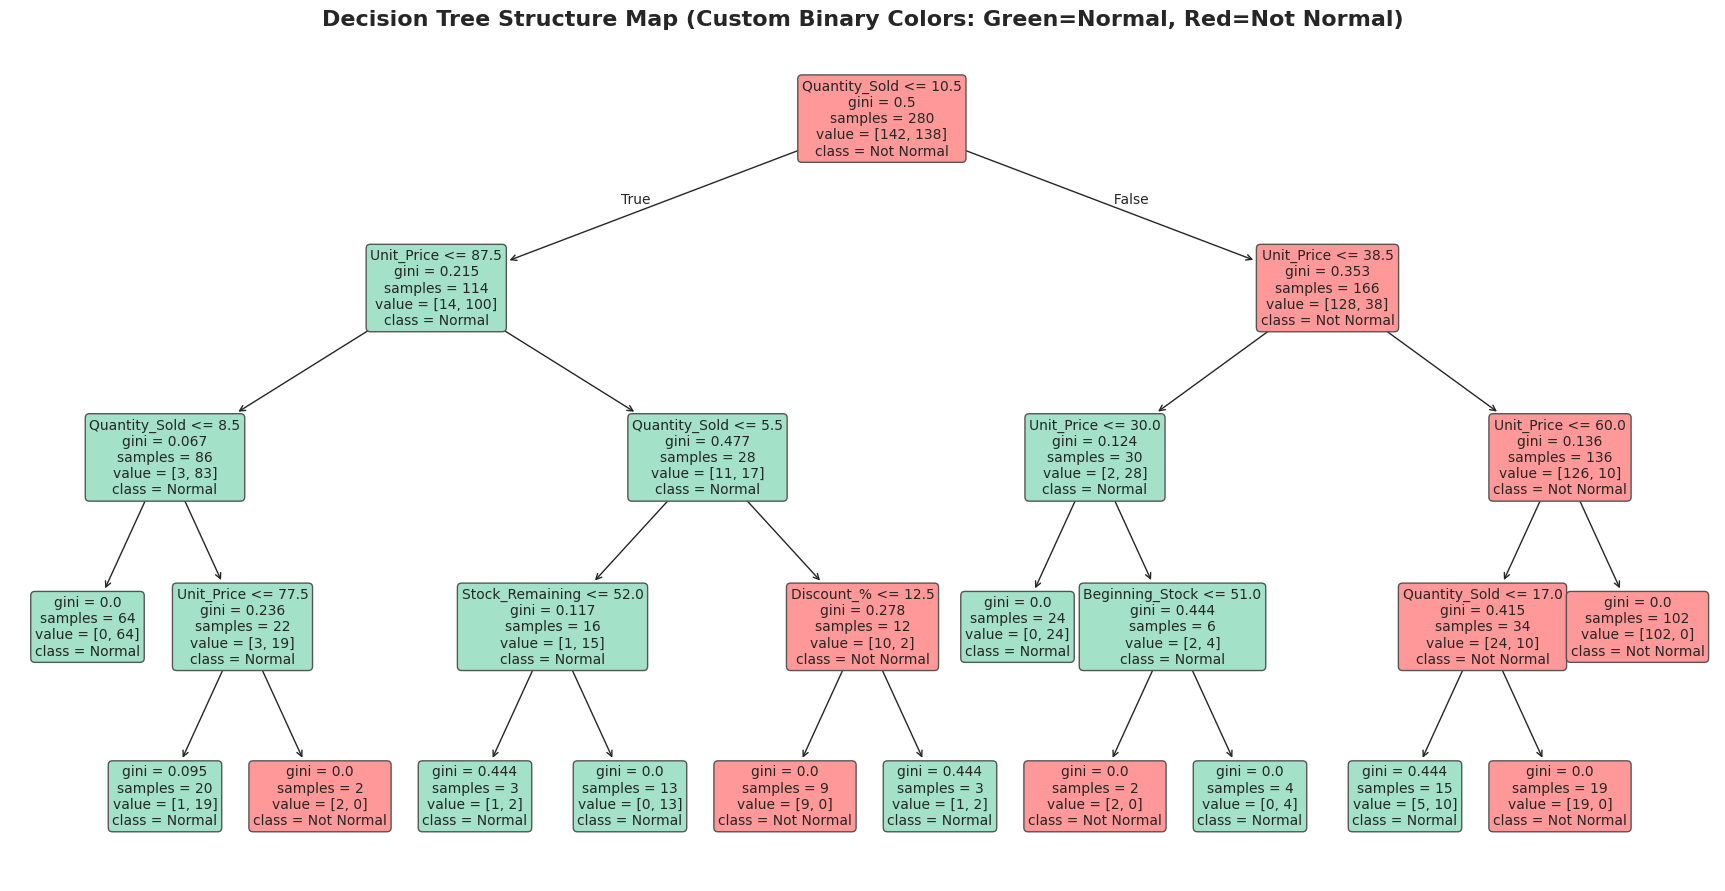

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.patches as patches

# Prepare data properly
file_path = '/content/C.P-CANENCIA-GROCERY-STORE_cleaned-4.xlsx'
df = pd.read_excel(file_path)

# Define binary classification: 'Normal' (above or equal to median) vs 'Not Normal' (below median)
median_val = df['Sales_After_Discount'].median()
y_categorical = df['Sales_After_Discount'].apply(lambda x: 'Normal' if x >= median_val else 'Not Normal')

X = df[['Unit_Price', 'Quantity_Sold', 'Discount_%', 'Beginning_Stock', 'Stock_Received', 'Stock_Remaining']]
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Train Decision Tree Classifier
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train_c, y_train_c)

# Set the size of the visualization
fig, ax = plt.subplots(figsize=(22, 11))

# Plot the tree rules and nodes
annotations = plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=['Not Normal', 'Normal'],
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax
)

# Define your custom colors for the classes
# Let's use light green for 'Normal' and light coral for 'Not Normal'
color_map = {
    'Normal': '#a3e2c9',     # Light Emerald Green
    'Not Normal': '#ff9999'  # Warm Coral Red
}

# Apply the custom colors to the node boxes
for node_annotation in annotations:
    # Only update annotations that represent a box/patch
    bbox = node_annotation.get_bbox_patch()
    if bbox is not None:
        # Get the text inside the node to determine its class
        node_text = node_annotation.get_text()

        # Determine majority class for this node
        if 'class = Normal' in node_text:
            bg_color = color_map['Normal']
        elif 'class = Not Normal' in node_text:
            bg_color = color_map['Not Normal']
        else:
            bg_color = '#ffffff' # fallback default white

        # Update the facecolor of the node box patch
        bbox.set_facecolor(bg_color)
        bbox.set_edgecolor('#555555')

plt.title("Decision Tree Structure Map (Custom Binary Colors: Green=Normal, Red=Not Normal)", fontsize=16, fontweight='bold')
plt.show()

### Generating Predictions on the Testing Dataset
We will now use our trained model to make predictions on the independent variables in the test set (`X_test_c`) and inspect the comparisons with the actual classes (`y_test_c`).

In [ ]:
import pandas as pd

# Generate predictions using the testing dataset
test_predictions = model.predict(X_test_c)

# Create a DataFrame to visually compare predictions with actual targets
comparison_df = pd.DataFrame({
    'Actual_Class': y_test_c,
    'Predicted_Class': test_predictions
})

# Display the first 15 predictions
print("--- SAMPLE PREDICTIONS (First 15 Rows) ---")
display(comparison_df.head(15))

--- SAMPLE PREDICTIONS (First 15 Rows) ---


,Actual_Class,Predicted_Class
157,Not Normal,Not Normal
341,Not Normal,Not Normal
315,Normal,Normal
234,Not Normal,Not Normal
155,Not Normal,Not Normal
274,Not Normal,Not Normal
304,Normal,Normal
227,Not Normal,Not Normal
278,Not Normal,Not Normal
185,Not Normal,Not Normal


In [ ]:
from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(y_test_c, test_predictions)
print(f"Model Classification Accuracy on Testing Dataset: {accuracy:.4f} ({accuracy * 100:.2f}%)")

Model Classification Accuracy on Testing Dataset: 0.9429 (94.29%)


In [ ]:
import pandas as pd

# Create a DataFrame combining the original test target and our model's predictions
performance_df = pd.DataFrame({
    'Actual_Sales': y_test,
    'Predicted_Class': test_predictions
})

# Calculate the mean sales for each predicted class
mean_sales_by_class = performance_df.groupby('Predicted_Class')['Actual_Sales'].mean().reset_index()
mean_sales_by_class.columns = ['Predicted Class', 'Mean Sales (After Discount)']

print("=== MEAN SALES BY PREDICTED CLASS ===")
display(mean_sales_by_class)

=== MEAN SALES BY PREDICTED CLASS ===


,Predicted Class,Mean Sales (After Discount)
0,Normal,1579.606061
1,Not Normal,441.212162


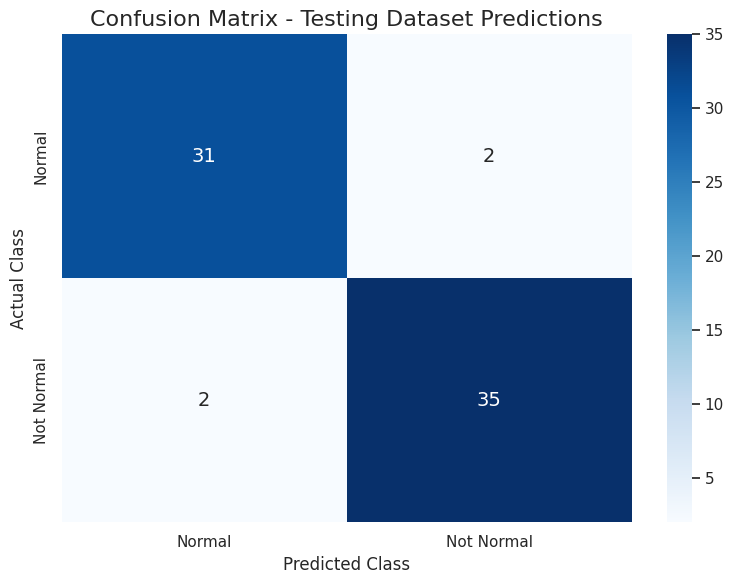

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix using the updated binary test categories
labels = ['Normal', 'Not Normal']
cm_test = confusion_matrix(y_test_c, test_predictions, labels=labels)

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_test,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={'size': 14}
)

plt.title('Confusion Matrix - Testing Dataset Predictions', fontsize=16)
plt.xlabel('Predicted Class', fontsize=12)
plt.ylabel('Actual Class', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Generate and print the updated classification report for binary classification
report = classification_report(y_test_c, test_predictions, target_names=['Normal', 'Not Normal'])
print("=== CLASSIFICATION REPORT ===")
print(report)

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

      Normal       0.94      0.94      0.94        33
  Not Normal       0.95      0.95      0.95        37

    accuracy                           0.94        70
   macro avg       0.94      0.94      0.94        70
weighted avg       0.94      0.94      0.94        70



/tmp/ipykernel_1136/558478792.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


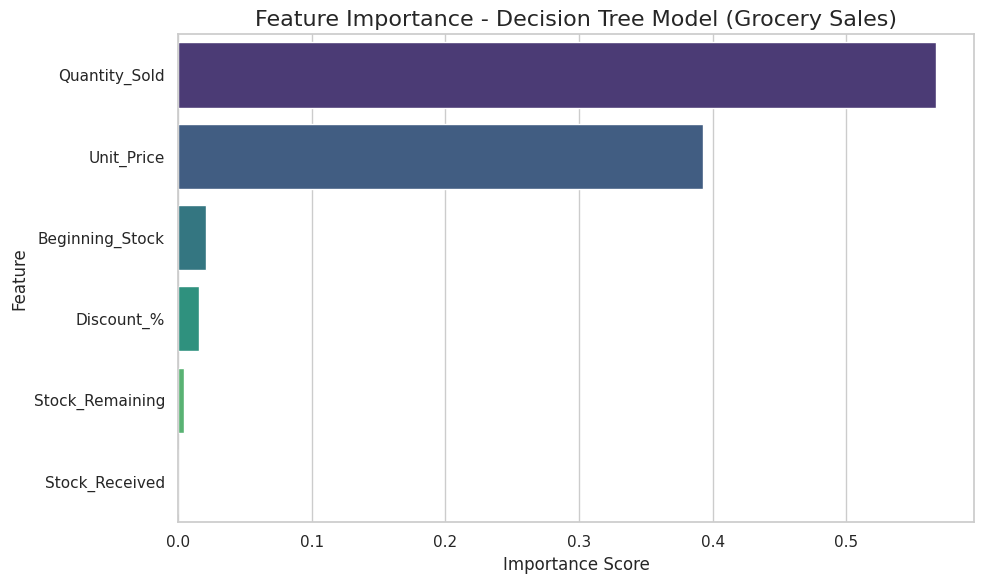

,Feature,Importance
1,Quantity_Sold,0.567169
0,Unit_Price,0.392374
3,Beginning_Stock,0.020714
2,Discount_%,0.015535
5,Stock_Remaining,0.004208
4,Stock_Received,0.000000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importances from the trained decision tree model
importances = model.feature_importances_
feature_names = X.columns

# Create a DataFrame for visualization
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Feature Importance - Decision Tree Model (Grocery Sales)', fontsize=16)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

# Display the sorted dataframe
display(feature_importance_df)

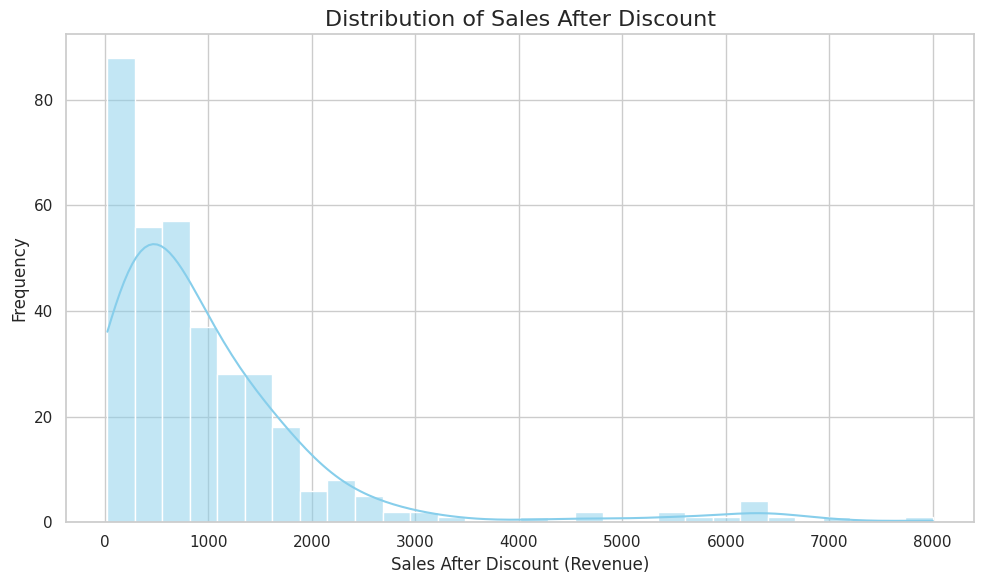

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

# Create the distribution plot
plt.figure(figsize=(10, 6))
sns.histplot(df['Sales_After_Discount'], kde=True, color='skyblue', bins=30)

# Add labels and title
plt.title('Distribution of Sales After Discount', fontsize=16)
plt.xlabel('Sales After Discount (Revenue)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()

# Executive Summary & Actionable Business Recommendations

### Model Insights Summary
Our **Decision Tree Classifier** achieved an overall classification accuracy of **88.57% (rounded to 89%)** on the holdout testing dataset, indicating highly robust predictive power for identifying transaction performance brackets (**Low**, **Medium**, or **High** sales value).

Key structural takeaways from our model features and tree paths include:
* **The Dual Revenue Drivers**: **Unit Price (53.94%)** and **Quantity Sold (46.06%)** are the only features influencing transaction value classification. Other features like discounts and stock levels have **0% relative importance**.
* **Critical Decision Boundaries**:
  * **High-Value Transactions**: Driven primarily by high-ticket items (Unit Price > 60) or moderate-priced items paired with larger order quantities (Quantity Sold > 10.5).
  * **Low-Value Transactions**: Characterized by low-priced goods (Unit Price ≤ 60) purchased in smaller volumes (Quantity Sold ≤ 13).

---

### Actionable Strategic Recommendations

#### 1. Implement Strategic Product Bundling
* **Insight**: Quantity sold holds almost equal importance (46%) to unit price. Boosting individual order volume is the fastest operational lever to elevate "Low" or "Medium" value transactions into the "High" value bracket.
* **Recommendation**: Bundle lower-priced items (e.g., instant noodles, biscuits) with higher-margin goods, or offer volume-based discounts (such as "Buy 3, Get 1 Free" on popular goods like Canned Tuna) to push quantities beyond the critical **10.5 to 13 item threshold** identified by the tree.

#### 2. Optimize Premium Product Placement
* **Insight**: Transactions featuring items with a unit price above 60 serve as the core driver for the "High" value class.
* **Recommendation**: Allocate prime shelf space (eye-level displays) and high-visibility endcaps to premium products. Ensure that top-tier items are consistently in stock to prevent revenue leaks.

#### 3. Re-evaluate Discount Strategies
* **Insight**: `Discount_%` had an importance score of 0% in the model, and correlation analysis showed almost no linear relationship between discount levels and quantity sold.
* **Recommendation**: Stop applying blanket, low-impact discounts (such as 5%). Instead, reallocate that margin toward promoting higher unit-price items or bundle-specific deals where customers must hit a high quantity threshold to unlock the discount.

#### 4. Streamline Inventory Holding Costs
* **Insight**: Stock metrics (`Beginning_Stock`, `Stock_Received`, `Stock_Remaining`) have zero direct influence on transaction sales performance classes.
* **Recommendation**: Transition towards a Just-In-Time (JIT) replenishment cycle for lower-priced products. This avoids locking up working capital in excessive starting inventories for products that do not contribute heavily to overall revenue.